# Python Code Summarization with Pretrained Transformers

This notebook fine-tunes pretrained sequence-to-sequence transformers to write a **natural-language docstring
for a Python function**. Four models are compared on the CodeXGLUE code-to-text dataset:
**T5-small, BART-base, PLBART-base and CodeT5-base**.

**Pipeline:** exploratory data analysis → tokenisation with optional comment removal → fine-tuning with the
Hugging Face `Seq2SeqTrainer` → evaluation with SacreBLEU and ROUGE → sample predictions on test data and on
new code.

**Author:** Kiana Hashemi

## Configuration

Paths and run settings come from environment variables, so the notebook runs unchanged locally, in Docker
or in CI:

| Variable | Default | Meaning |
|---|---|---|
| `SUMMARIZATION_WORK_DIR` | `../work` | where model checkpoints are written |
| `QUICK_RUN` | `0` | `1` = smoke test: 100 samples per split, 10 % of them per run, 1 epoch per model |

> **About the saved outputs:** they come from real GPU runs in separate sessions, with **different data sizes**.
> The exploratory analysis uses the 70 % / 60 % / 50 % subsets shown below, and the model runs use the sizes in
> the *Models and Results* section. The configuration cell was added for portability after those runs, so it
> has no stored output, and the widget-based download progress bars were removed from the outputs.

In [ ]:
import os

WORK_DIR = os.environ.get("SUMMARIZATION_WORK_DIR", "../work")
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"
QUICK_SAMPLES = 100

os.makedirs(WORK_DIR, exist_ok=True)
print(f"WORK_DIR={WORK_DIR}  QUICK_RUN={QUICK_RUN}")

In [ ]:
# Importing Required Libraries
import os
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate
import re
import random

# Suppress warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Disable W&B
os.environ["WANDB_DISABLED"] = "true"

# Dataset Analyze and EDA

In [7]:
# Load the Dataset
dataset = load_dataset("google/code_x_glue_ct_code_to_text", "python")
if QUICK_RUN:
    dataset = {split: dataset[split].select(range(QUICK_SAMPLES)) for split in dataset}

train_data = dataset["train"].select(range(int(len(dataset["train"]) * 0.7)))
validation_data = dataset["validation"].select(range(int(len(dataset["validation"]) * 0.6)))
test_data = dataset["test"].select(range(int(len(dataset["test"]) * 0.5)))

print("Subset Train Split Size:", len(train_data))
print("Validation Split Size:", len(validation_data))
print("Test Split Size:", len(test_data))

Subset Train Split Size: 176274
Validation Split Size: 8348
Test Split Size: 7459


In [8]:
# Convert to Pandas DataFrame for Analysis
train_df = pd.DataFrame(train_data)
validation_df = pd.DataFrame(validation_data)
test_df = pd.DataFrame(test_data)

# Basic Data Overview
print("Train Dataset Columns:", train_df.columns)
print("First Few Rows of Train Dataset:")
print(train_df.head())

Train Dataset Columns: Index(['id', 'repo', 'path', 'func_name', 'original_string', 'language',
       'code', 'code_tokens', 'docstring', 'docstring_tokens', 'sha', 'url'],
      dtype='object')
First Few Rows of Train Dataset:
   id            repo                     path                    func_name  \
0   0  proycon/pynlpl  pynlpl/formats/folia.py      AbstractElement.settext   
1   1  proycon/pynlpl  pynlpl/formats/folia.py  AbstractElement.setdocument   
2   2  proycon/pynlpl  pynlpl/formats/folia.py      AbstractElement.addable   
3   3  proycon/pynlpl  pynlpl/formats/folia.py   AbstractElement.postappend   
4   4  proycon/pynlpl  pynlpl/formats/folia.py   AbstractElement.updatetext   

                                     original_string language  \
0  def settext(self, text, cls='current'):\n     ...   python   
1  def setdocument(self, doc):\n        """Associ...   python   
2  def addable(Class, parent, set=None, raiseexce...   python   
3  def postappend(self):\n        ""

In [9]:
# Data Analysis
train_df['code_length'] = train_df['code'].apply(len)
train_df['docstring_length'] = train_df['docstring'].apply(len)

# Summary statistics
print("\nTrain Code Length Statistics:")
print(train_df['code_length'].describe())
print("\nTrain Docstring Length Statistics:")
print(train_df['docstring_length'].describe())


Train Code Length Statistics:
count    176274.000000
mean        896.792068
std         828.066150
min          89.000000
25%         378.000000
50%         628.000000
75%        1111.000000
max       19761.000000
Name: code_length, dtype: float64

Train Docstring Length Statistics:
count    176274.000000
mean        261.602443
std         431.738237
min           3.000000
25%          51.000000
50%         123.000000
75%         309.000000
max       17283.000000
Name: docstring_length, dtype: float64


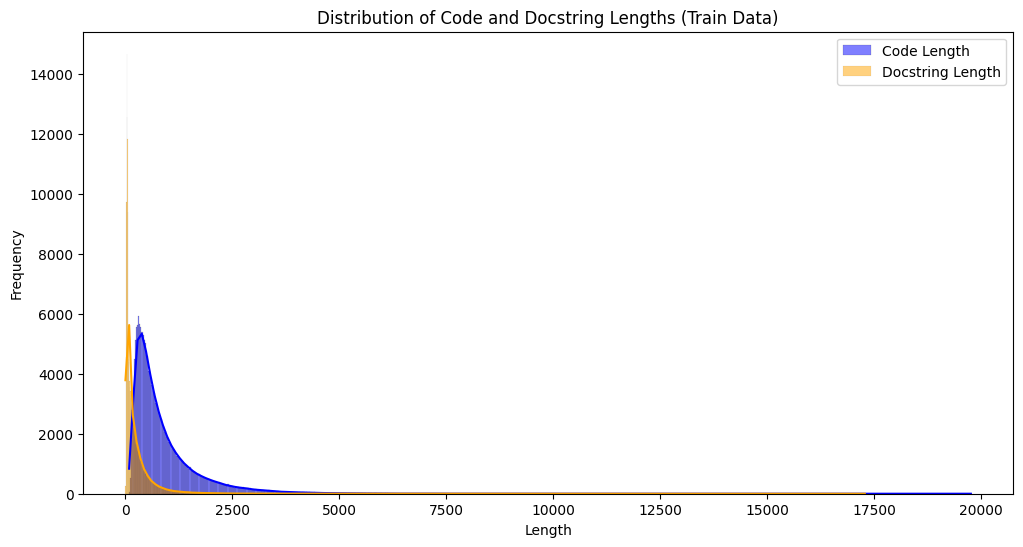

In [10]:
# Visualization
plt.figure(figsize=(12, 6))
sns.histplot(train_df['code_length'], kde=True, color='blue', label='Code Length')
sns.histplot(train_df['docstring_length'], kde=True, color='orange', label='Docstring Length')
plt.legend()
plt.title('Distribution of Code and Docstring Lengths (Train Data)')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

In [11]:
# Inspect Samples
sample_data = train_df.sample(5)
print("\nSample Data (Train Dataset):")
for idx, row in sample_data.iterrows():
    print(f"Code Snippet:\n{row['code']}\n")
    print(f"Docstring:\n{row['docstring']}\n{'-'*80}")


Sample Data (Train Dataset):
Code Snippet:
def _insert_data(self, connection, name, value, timestamp, interval, config):
    '''Helper to insert data into cql.'''
    cursor = connection.cursor()
    try:
      stmt = self._insert_stmt(name, value, timestamp, interval, config)
      if stmt:
        cursor.execute(stmt)
    finally:
      cursor.close()

Docstring:
Helper to insert data into cql.
--------------------------------------------------------------------------------
Code Snippet:
def FetchFileContent(self):
    """Fetch as much as the file's content as possible.

    This drains the pending_files store by checking which blobs we already have
    in the store and issuing calls to the client to receive outstanding blobs.
    """
    if not self.state.pending_files:
      return

    # Check what blobs we already have in the blob store.
    blob_hashes = []
    for file_tracker in itervalues(self.state.pending_files):
      for hash_response in file_tracker.get("hash_list", [])

In [12]:
# Validate and Test Analysis
validation_df['code_length'] = validation_df['code'].apply(len)
validation_df['docstring_length'] = validation_df['docstring'].apply(len)

print("\nValidation Code Length Statistics:")
print(validation_df['code_length'].describe())
print("\nValidation Docstring Length Statistics:")
print(validation_df['docstring_length'].describe())


Validation Code Length Statistics:
count     8348.000000
mean      1020.262338
std        995.880089
min        107.000000
25%        407.000000
50%        700.000000
75%       1264.000000
max      12142.000000
Name: code_length, dtype: float64

Validation Docstring Length Statistics:
count    8348.000000
mean      344.589003
std       559.358016
min         4.000000
25%        58.000000
50%       165.000000
75%       403.250000
max      8819.000000
Name: docstring_length, dtype: float64


In [13]:
print("Missing Values in Train Data:")
print(train_df.isnull().sum())

print("\nMissing Values in Validation Data:")
print(validation_df.isnull().sum())

print("\nMissing Values in Test Data:")
print(test_df.isnull().sum())

Missing Values in Train Data:
id                  0
repo                0
path                0
func_name           0
original_string     0
language            0
code                0
code_tokens         0
docstring           0
docstring_tokens    0
sha                 0
url                 0
code_length         0
docstring_length    0
dtype: int64

Missing Values in Validation Data:
id                  0
repo                0
path                0
func_name           0
original_string     0
language            0
code                0
code_tokens         0
docstring           0
docstring_tokens    0
sha                 0
url                 0
code_length         0
docstring_length    0
dtype: int64

Missing Values in Test Data:
id                  0
repo                0
path                0
func_name           0
original_string     0
language            0
code                0
code_tokens         0
docstring           0
docstring_tokens    0
sha                 0
url                 

In [14]:
# Convert list-like columns to strings for duplicate checks
train_df_hashed = train_df.applymap(lambda x: str(x) if isinstance(x, list) else x)
validation_df_hashed = validation_df.applymap(lambda x: str(x) if isinstance(x, list) else x)
test_df_hashed = test_df.applymap(lambda x: str(x) if isinstance(x, list) else x)

train_duplicates = train_df_hashed.duplicated().sum()
validation_duplicates = validation_df_hashed.duplicated().sum()
test_duplicates = test_df_hashed.duplicated().sum()

print(f"\nDuplicate Rows in Train Data: {train_duplicates}")
print(f"Duplicate Rows in Validation Data: {validation_duplicates}")
print(f"Duplicate Rows in Test Data: {test_duplicates}")


Duplicate Rows in Train Data: 0
Duplicate Rows in Validation Data: 0
Duplicate Rows in Test Data: 0


In [15]:
all_code_tokens = [token for tokens in train_df['code_tokens'] for token in tokens]

# Count frequency
code_token_freq = Counter(all_code_tokens)

top_20_code_tokens = code_token_freq.most_common(20)
print("Top 20 Most Common Code Tokens (Train Data):")
for token, freq in top_20_code_tokens:
    print(f"{token}: {freq}")


Top 20 Most Common Code Tokens (Train Data):
(: 1421987
): 1421979
.: 1384344
,: 1098802
=: 955924
:: 817031
self: 495648
[: 387475
]: 387475
if: 283214
return: 195422
def: 186197
in: 149539
None: 138029
for: 105580
*: 104342
1: 87314
0: 86772
not: 86420
else: 74077


In [16]:
all_docstring_tokens = [token for tokens in train_df['docstring_tokens'] for token in tokens]

# Count frequency
docstring_token_freq = Counter(all_docstring_tokens)

top_20_doc_tokens = docstring_token_freq.most_common(20)
print("\nTop 20 Most Common Docstring Tokens (Train Data):")
for token, freq in top_20_doc_tokens:
    print(f"{token}: {freq}")


Top 20 Most Common Docstring Tokens (Train Data):
.: 154561
the: 132700
a: 85453
to: 49372
of: 46674
and: 31882
for: 28994
in: 23063
from: 20314
is: 18883
an: 16468
-: 15347
with: 14329
given: 14188
that: 12390
if: 12173
Return: 11643
file: 11327
all: 10804
this: 10392


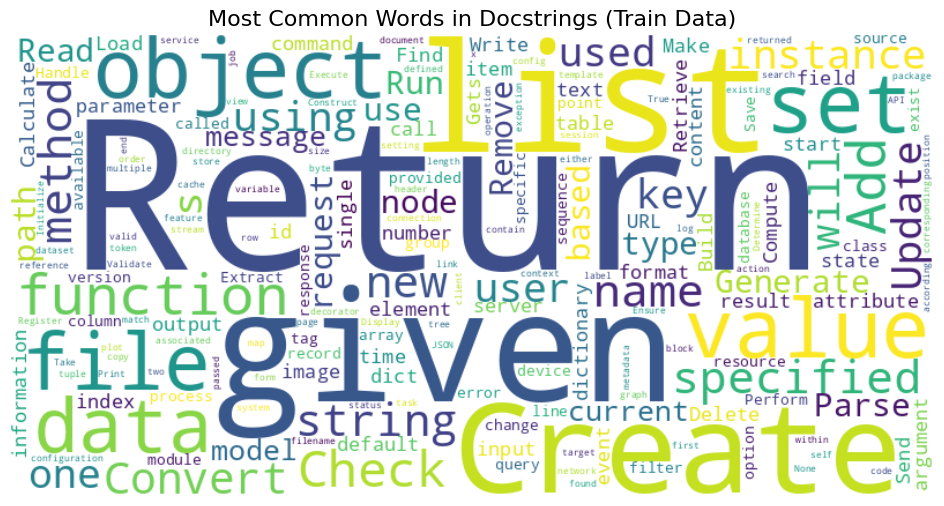

In [17]:
docstring_text = " ".join(all_docstring_tokens)

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(docstring_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud.to_image(), interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Docstrings (Train Data)', fontsize=16)
plt.show()

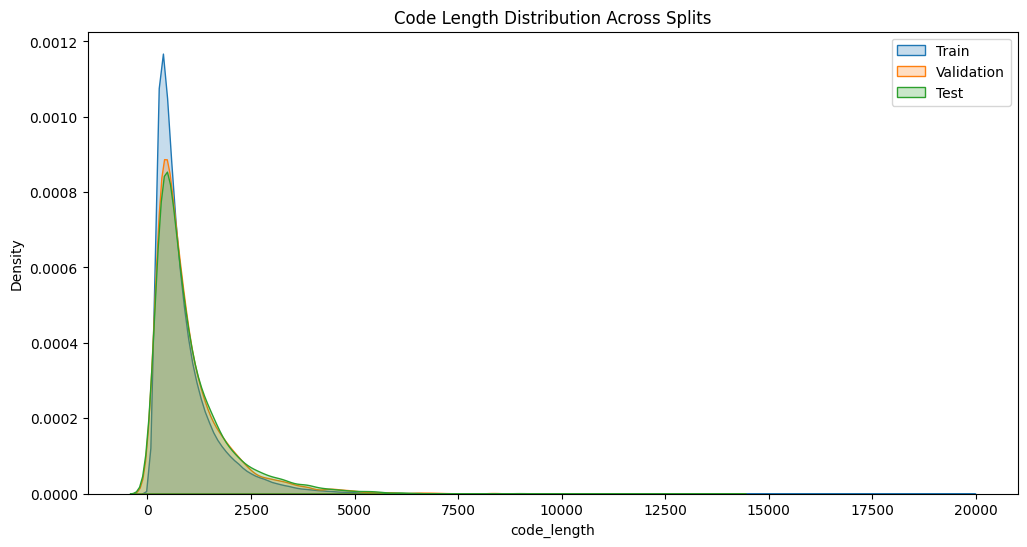

In [18]:
plt.figure(figsize=(12, 6))

# Plot code length for train, val, test in one figure
sns.kdeplot(train_df['code_length'], shade=True, label='Train')
sns.kdeplot(validation_df['code_length'], shade=True, label='Validation')
sns.kdeplot(test_df_hashed['code'].apply(len), shade=True, label='Test')  # or test_df if you also computed code_length
plt.title("Code Length Distribution Across Splits")
plt.legend()
plt.show()

# Preprocess

In [19]:
def remove_comments_python(code: str) -> str:
    # 75% chance to remove comments
    if random.random() < 0.75:
        # Remove single-line comments
        code = re.sub(r'#.*', '', code)
        # Remove multi-line comments (''' or """)
        code = re.sub(r'(\'\'\'(.*?)\'\'\'|\"\"\"(.*?)\"\"\")', '', code, flags=re.DOTALL)
    
    return code.strip()

> **Important: this step can leak the target.** In this dataset the `code` field includes the function's
> docstring, which is also the target. `remove_comments_python` removes comments and docstrings only 75 % of the
> time, so about a quarter of the inputs, in training and in testing, still contain the answer. All scores below
> are inflated by this, as the sample predictions show when a model simply copies the docstring. Removing the
> docstring from every input and retraining would give an honest estimate.

In [20]:
def tokenize_dataset(raw_dataset, tokenizer, model_name, 
                     max_source_len=256, max_target_len=64):
    
    def preprocess_function(examples):
        clean_code = [remove_comments_python(c) for c in examples["code"]]
        
        if "t5" in model_name.lower():
            inputs = ["summarize: " + c for c in clean_code]
        else:
            inputs = [c for c in clean_code]
        
        # 1) Tokenize the code
        model_inputs = tokenizer(
            inputs,
            max_length=max_source_len,
            padding="max_length",
            truncation=True
        )
        
        # 2) Tokenize the docstring
        with tokenizer.as_target_tokenizer():
            labels = tokenizer(
                examples["docstring"],
                max_length=max_target_len,
                padding="max_length",
                truncation=True
            )
        
        model_inputs["labels"] = labels["input_ids"]
        
        return model_inputs
    
    tokenized_ds = raw_dataset.map(
        preprocess_function,
        batched=True,
        remove_columns=raw_dataset.column_names
    )
    
    return tokenized_ds

# Functions

In [21]:
def plot_learning_curve(log_history, model_name="Model"):
    import matplotlib.pyplot as plt
    
    train_loss = []
    eval_loss = []
    steps_train = []
    steps_eval = []
    
    for entry in log_history:
        if "loss" in entry: 
            train_loss.append(entry["loss"])
            steps_train.append(entry["step"])
        if "eval_loss" in entry:
            eval_loss.append(entry["eval_loss"])
            steps_eval.append(entry["step"])

    plt.figure(figsize=(8, 5))
    if train_loss:
        plt.plot(steps_train, train_loss, label="Train Loss", color="blue", marker="o")
    if eval_loss:
        plt.plot(steps_eval, eval_loss, label="Eval Loss", color="red", marker="x")
    plt.title(f"Training Curve - {model_name}")
    plt.xlabel("Steps")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [22]:
bleu_metric = evaluate.load("sacrebleu")
rouge_metric = evaluate.load("rouge")

def compute_metrics(eval_pred, tokenizer, lang="python"):
    predictions, labels = eval_pred
    
    # Decode predictions and labels to strings
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    
    # SacreBLEU
    bleu = bleu_metric.compute(
        predictions=decoded_preds, 
        references=[[l] for l in decoded_labels]
    )
    
    # ROUGE
    rouge = rouge_metric.compute(
        predictions=decoded_preds, 
        references=decoded_labels
    )
    
    return {
        "sacrebleu": bleu["score"],    
        "rouge1": rouge["rouge1"],
        "rouge2": rouge["rouge2"],
        "rougeL": rouge["rougeL"],
        "rougeLsum": rouge["rougeLsum"],
    }

## Training Model

In [23]:
def train_model(
    model_checkpoint,
    train_data,
    val_data,
    output_dir="model-output",
    epochs=1,
    batch_size=2,
    lr=5e-5,
    max_source_len=256,
    max_target_len=64,
    lang="python",
    compute_metrics_fn=None
):
    # 1) Load tokenizer and model
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint).to(device)
    
    # 2) Preprocessing and Tokenize train & validation splits
    tokenized_train = tokenize_dataset(train_data,tokenizer,model_checkpoint)
    tokenized_val = tokenize_dataset(val_data,tokenizer,model_checkpoint)
    
    # 3) Data collator for seq2seq models
    data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
    
    # 4) Training arguments
    training_args = Seq2SeqTrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",        
        logging_steps=10,                 
        disable_tqdm=False,               
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        learning_rate=lr,
        predict_with_generate=True,
        fp16=True if device == "cuda" else False, 
        load_best_model_at_end=True,
        metric_for_best_model="sacrebleu",  
        greater_is_better=True,
    )
    
    # 5) Initialize Trainer
    trainer = Seq2SeqTrainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_val,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=lambda eval_pred: compute_metrics_fn(eval_pred, tokenizer, lang=lang)
        if compute_metrics_fn is not None
        else None
    )

    # 6) Train
    train_result = trainer.train()
    return trainer, model, tokenizer, train_result

In [24]:
def evaluate_on_test(trainer, test_data, lang="python"):
    # Tokenize test data
    tokenized_test = tokenize_dataset(test_data,trainer.tokenizer,trainer.model.config._name_or_path.lower())

    # Evaluate
    test_metrics = trainer.evaluate(tokenized_test)
    return test_metrics

In [25]:
def generate_predictions(trainer, code_snippets, num_beams=4, max_length=64):
    inputs = trainer.tokenizer(
        code_snippets,
        return_tensors="pt", 
        padding=True,
        truncation=True
    ).to(trainer.model.device)

    with torch.no_grad():
        outputs = trainer.model.generate(
            **inputs, 
            num_beams=num_beams, 
            max_length=max_length
        )
    preds = trainer.tokenizer.batch_decode(outputs, skip_special_tokens=True)
    return preds

# Models and Results

In [26]:
# --------------------------------------
# 1) Dictionary of Model Names / Checkpoints
# --------------------------------------
model_names = {
    "T5-small": "t5-small",
    "PLBART-base": "uclanlp/plbart-base",
    "BART-base": "facebook/bart-base",
    "CodeT5": "Salesforce/codet5-base",
}

results = {}

In [27]:
static_code_snippets = [
    # Example 1: Find the Longest Palindromic Substring
    """def longest_palindromic_substring(s):
        def expand_around_center(left, right):
            while left >= 0 and right < len(s) and s[left] == s[right]:
                left -= 1
                right += 1
            return s[left + 1:right]

        result = ""
        for i in range(len(s)):
            odd_palindrome = expand_around_center(i, i)
            even_palindrome = expand_around_center(i, i + 1)
            result = max(result, odd_palindrome, even_palindrome, key=len)
        return result""",

    # Example 2: Flatten a Nested List
    """def flatten_nested_list(nested_list):
        result = []
        for element in nested_list:
            if isinstance(element, list):
                result.extend(flatten_nested_list(element))
            else:
                result.append(element)
        return result""",

    # Example 3: Generate Fibonacci Numbers Using Memoization
    """def fibonacci(n, memo={}):
        if n in memo:
            return memo[n]
        if n <= 1:
            return n
        memo[n] = fibonacci(n - 1, memo) + fibonacci(n - 2, memo)
        return memo[n]""",

    # Example 4: Check for Valid Parentheses
    """def is_valid_parentheses(s):
        stack = []
        mapping = {')': '(', '}': '{', ']': '['}
        for char in s:
            if char in mapping:
                top_element = stack.pop() if stack else '#'
                if mapping[char] != top_element:
                    return False
            else:
                stack.append(char)
        return not stack""",

    # Example 5: Perform Binary Search
    """def binary_search(nums, target):
        left, right = 0, len(nums) - 1
        while left <= right:
            mid = (left + right) // 2
            if nums[mid] == target:
                return mid
            elif nums[mid] < target:
                left = mid + 1
            else:
                right = mid - 1
        return -1"""
]

In [ ]:
def first_rows(split, fraction):
    return dataset[split].select(range(int(len(dataset[split]) * fraction)))


def run_experiment(labels, epochs, train_fraction, validation_fraction, test_fraction):
    results = {}
    train_subset = first_rows("train", train_fraction)
    validation_subset = first_rows("validation", validation_fraction)
    test_subset = first_rows("test", test_fraction)

    for label in labels:
        ckpt = model_names[label]
        print(f"\n\n==========================")
        print(f"Training Model: {label} ({ckpt})")
        print(f"==========================\n")

        # (A) TRAIN
        trainer, model, tokenizer, train_result = train_model(
            model_checkpoint=ckpt,
            train_data=train_subset,
            val_data=validation_subset,
            output_dir=os.path.join(WORK_DIR, f"{label}-output"),
            epochs=epochs,
            batch_size=2,
            lr=5e-5,
            max_source_len=256,
            max_target_len=64,
            lang="python",
            compute_metrics_fn=compute_metrics
        )

        # (B) PLOT TRAINING CURVES
        plot_learning_curve(trainer.state.log_history, model_name=label)

        # (C) EVALUATE ON TEST
        print(f"\nEvaluating Model: {label} on Test Set")
        test_metrics = evaluate_on_test(trainer, test_subset, lang="python")
        print(f"Test Metrics for {label}:\n{test_metrics}\n")
        results[label] = test_metrics

        # (D) SHOW SAMPLE PREDICTIONS ON VALIDATION OR TEST SET
        print(f"Sample Predictions for {label} on Test Data:\n")
        sample_df = test_subset.to_pandas().sample(3, random_state=42)
    
        # Preprocess code snippets to remove comments
        code_snippets = sample_df["code"].tolist()
        cleaned_code_snippets = [remove_comments_python(code) for code in code_snippets]
    
        predictions = generate_predictions(
            trainer, 
            cleaned_code_snippets,
            num_beams=4,
            max_length=64
        )
    
        print(f"\nSample Predictions for {label}:\n")
        for i, pred in enumerate(predictions):
            print(f"Code Snippet (Cleaned):\n{cleaned_code_snippets[i]}\n")
            print(f"Reference:\n{sample_df['docstring'].iloc[i]}\n")
            print(f"Prediction:\n{pred}")
            print("-" * 80)


        # (E) EVALUATE ON EXTERNAL CODE SNIPPETS
        print(f"\nStatic Python Code Evaluation for {label}:\n")

        static_predictions = generate_predictions(
            trainer,
            static_code_snippets,
            num_beams=4,
            max_length=64
        )

        for i, static_pred in enumerate(static_predictions):
            print(f"Code Snippet:\n{static_code_snippets[i]}\n")
            print(f"Prediction:\n{static_pred}")
            print("-" * 80)
    
        print("\n\n")

    # --------------------------------------
    # 3) Print Final Results
    # --------------------------------------
    print("All Validation Results (Dictionary):")
    for model_label, metric_vals in results.items():
        print(f"{model_label} -> {metric_vals}")


# Settings of the stored runs. See the note above for how they were recovered.
SMALL_RUN = dict(epochs=4, train_fraction=0.04, validation_fraction=0.02, test_fraction=0.02)
LARGE_RUN = dict(epochs=1, train_fraction=0.7, validation_fraction=0.6, test_fraction=0.5)
if QUICK_RUN:
    SMALL_RUN = dict(epochs=1, train_fraction=0.1, validation_fraction=0.1, test_fraction=0.1)
    LARGE_RUN = SMALL_RUN

## The Three Runs

The models were trained in three separate sessions. Each setting below comes from that run's own training log
(steps = epochs × samples ÷ batch size 2) and evaluation size:

| Run | Models | Epochs | Training samples | Test samples | Training time (GPU) |
|---|---|---:|---:|---:|---|
| A | T5-small, PLBART-base | 4 | 10,072 (first 4 %) | 298 (first 2 %) | 28 and 34 min |
| B | BART-base, CodeT5 | 4 | 10,072 (first 4 %) | 298 (first 2 %) | 34 and 59 min |
| C | CodeT5 | 1 | 176,274 (first 70 %) | 7,459 (first 50 %) | 4 h 37 min |

The validation sizes are not recorded in the logs, so `validation_fraction` is an assumption: `0.02` for runs A and
B, and `0.6` for run C, the fraction used in the data cell above.



Training Model: T5-small (t5-small)



Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Sacrebleu,Rouge1,Rouge2,Rougel,Rougelsum
1,1.611200,2.104017,2.355347,0.290930,0.188096,0.272638,0.272447
2,1.388400,2.031534,2.645264,0.297942,0.185978,0.279647,0.279739
3,1.326000,2.012433,2.162404,0.296413,0.187587,0.279235,0.279671
4,1.297000,2.004211,2.682178,0.302706,0.187719,0.282557,0.283484


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


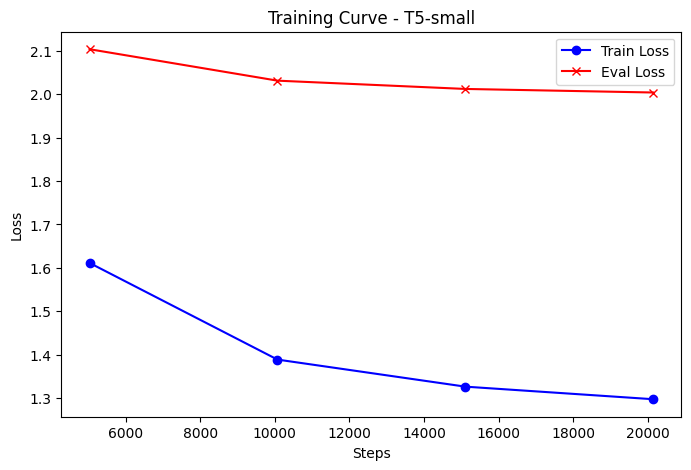


Evaluating Model: T5-small on Test Set


Test Metrics for T5-small:
{'eval_loss': 1.3468903303146362, 'eval_sacrebleu': 5.187574283176672, 'eval_rouge1': 0.3355998078435134, 'eval_rouge2': 0.21458761224414374, 'eval_rougeL': 0.3167011162066581, 'eval_rougeLsum': 0.318168879912491, 'eval_runtime': 37.9704, 'eval_samples_per_second': 7.848, 'eval_steps_per_second': 3.924, 'epoch': 4.0}

Sample Predictions for T5-small on Test Data:


Sample Predictions for T5-small:

Code Snippet (Cleaned):
def dispose_orm():
    
    log.debug("Disposing DB connection pool (PID %s)", os.getpid())
    global engine
    global Session

    if Session:
        Session.remove()
        Session = None
    if engine:
        engine.dispose()
        engine = None

Reference:
Properly close pooled database connections

Prediction:
Dispose DB connection pool (PID %s), os.getpid(), os.getpid(), os.getpid(), os.getpid(), os.getpid(), os.getpid(), 
--------------------------------------------------------------------------------
Code Snippet (Cleaned):
de

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Sacrebleu,Rouge1,Rouge2,Rougel,Rougelsum
1,1.191800,2.122359,2.434542,0.276906,0.176268,0.255246,0.256654
2,0.803700,2.197422,0.844941,0.215672,0.138125,0.198732,0.199980
3,0.560700,2.339764,2.482399,0.284109,0.179017,0.260928,0.261755
4,0.384100,2.490232,2.737735,0.288533,0.181090,0.266469,0.267263


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 2}
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 2}
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-defau

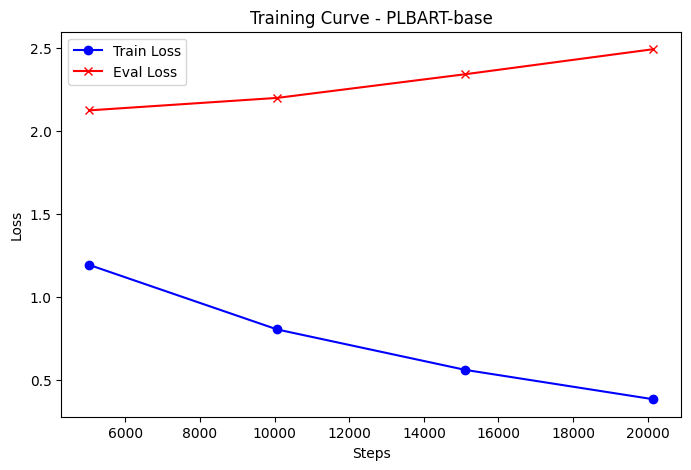


Evaluating Model: PLBART-base on Test Set


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Test Metrics for PLBART-base:
{'eval_loss': 1.3696107864379883, 'eval_sacrebleu': 5.985738787424797, 'eval_rouge1': 0.35365800510163514, 'eval_rouge2': 0.2265062627239222, 'eval_rougeL': 0.3334196769569123, 'eval_rougeLsum': 0.334374864357196, 'eval_runtime': 30.628, 'eval_samples_per_second': 9.73, 'eval_steps_per_second': 4.865, 'epoch': 4.0}

Sample Predictions for PLBART-base on Test Data:


Sample Predictions for PLBART-base:

Code Snippet (Cleaned):
def dispose_orm():
    
    log.debug("Disposing DB connection pool (PID %s)", os.getpid())
    global engine
    global Session

    if Session:
        Session.remove()
        Session = None
    if engine:
        engine.dispose()
        engine = None

Reference:
Properly close pooled database connections

Prediction:
Disposes the DB connection pool
--------------------------------------------------------------------------------
Code Snippet (Cleaned):
def check_for_wildcard_key(self,
                               wildcard_key, b

In [24]:
# Run A
run_experiment(["T5-small", "PLBART-base"], **SMALL_RUN)




Training Model: BART-base (facebook/bart-base)



Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Sacrebleu,Rouge1,Rouge2,Rougel,Rougelsum
1,1.283600,1.566172,4.859312,0.298413,0.165627,0.279997,0.289082
2,0.907400,1.544475,4.401213,0.297944,0.160837,0.280710,0.288736
3,0.743400,1.562656,4.849942,0.301897,0.168922,0.283666,0.290066
4,0.628800,1.599624,5.110354,0.299038,0.163512,0.281641,0.289938


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'early_stopping': True, 'num_beams': 4, 'no_repeat_ngram_size': 3, 'forced_bos_token_id': 0, 'forced_eos_token_id': 2}
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'early_stopping': True, 'num_beams': 4, 'no_repeat_ngram_size': 3, 'forced_bos_token_id': 0, 'forced_eos_token_id': 2}
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file

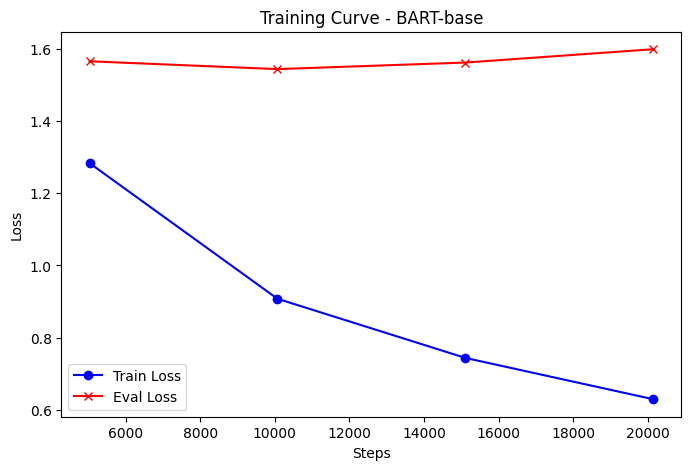


Evaluating Model: BART-base on Test Set


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Test Metrics for BART-base:
{'eval_loss': 1.1922454833984375, 'eval_sacrebleu': 5.6337218688912065, 'eval_rouge1': 0.34398231602002827, 'eval_rouge2': 0.21073386111219225, 'eval_rougeL': 0.325157728085286, 'eval_rougeLsum': 0.3331475997842517, 'eval_runtime': 35.4973, 'eval_samples_per_second': 8.395, 'eval_steps_per_second': 4.198, 'epoch': 4.0}

Sample Predictions for BART-base on Test Data:


Sample Predictions for BART-base:

Code Snippet (Cleaned):
def dispose_orm():
    
    log.debug("Disposing DB connection pool (PID %s)", os.getpid())
    global engine
    global Session

    if Session:
        Session.remove()
        Session = None
    if engine:
        engine.dispose()
        engine = None

Reference:
Properly close pooled database connections

Prediction:
Disposures the DB connection pool.
--------------------------------------------------------------------------------
Code Snippet (Cleaned):
def check_for_wildcard_key(self,
                               wildcard_key, 

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Sacrebleu,Rouge1,Rouge2,Rougel,Rougelsum
1,1.071300,1.727071,4.279781,0.342470,0.199692,0.312220,0.329983
2,0.793900,1.739512,3.212998,0.328815,0.198977,0.303233,0.316469
3,0.634300,1.816467,3.105371,0.321593,0.195906,0.294890,0.309542
4,0.528200,1.883304,3.334030,0.327395,0.199140,0.299139,0.314260


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


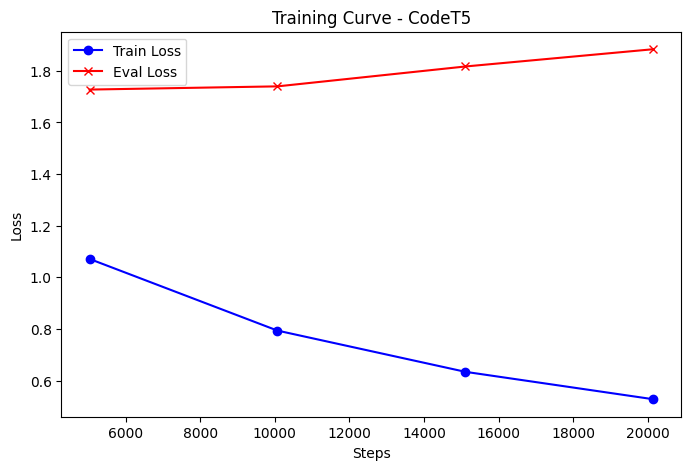


Evaluating Model: CodeT5 on Test Set


Test Metrics for CodeT5:
{'eval_loss': 1.0364047288894653, 'eval_sacrebleu': 10.23544695120017, 'eval_rouge1': 0.4083648834292958, 'eval_rouge2': 0.2592772518855013, 'eval_rougeL': 0.3808529840364925, 'eval_rougeLsum': 0.39881113962549464, 'eval_runtime': 66.9969, 'eval_samples_per_second': 4.448, 'eval_steps_per_second': 2.224, 'epoch': 4.0}

Sample Predictions for CodeT5 on Test Data:


Sample Predictions for CodeT5:

Code Snippet (Cleaned):
def dispose_orm():
    
    log.debug("Disposing DB connection pool (PID %s)", os.getpid())
    global engine
    global Session

    if Session:
        Session.remove()
        Session = None
    if engine:
        engine.dispose()
        engine = None

Reference:
Properly close pooled database connections

Prediction:
Disposes the DB connection pool.

    :return:
--------------------------------------------------------------------------------
Code Snippet (Cleaned):
def check_for_wildcard_key(self,
                               wildcard_key

In [24]:
# Run B
run_experiment(["BART-base", "CodeT5"], **SMALL_RUN)




Training Model: CodeT5 (Salesforce/codet5-base)



Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Epoch,Training Loss,Validation Loss,Sacrebleu,Rouge1,Rouge2,Rougel,Rougelsum
1,0.997400,1.094649,7.301585,0.392635,0.249566,0.368366,0.379968


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


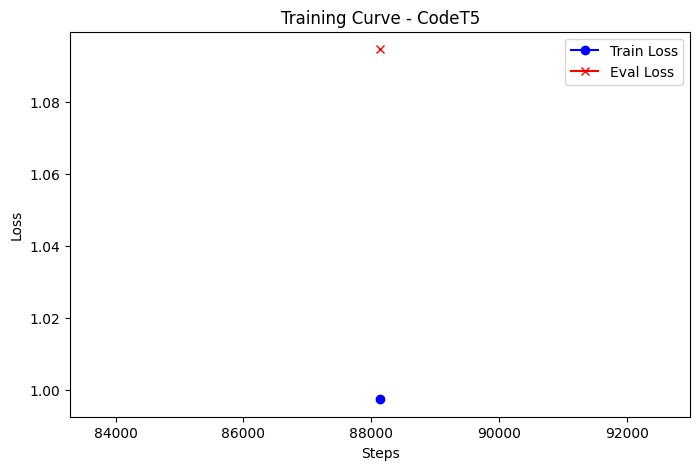


Evaluating Model: CodeT5 on Test Set


Test Metrics for CodeT5:
{'eval_loss': 1.0160890817642212, 'eval_sacrebleu': 7.596003290581764, 'eval_rouge1': 0.4032947760158906, 'eval_rouge2': 0.25623454337343454, 'eval_rougeL': 0.3780430739616395, 'eval_rougeLsum': 0.3898699280692074, 'eval_runtime': 1574.8593, 'eval_samples_per_second': 4.736, 'eval_steps_per_second': 2.368, 'epoch': 1.0}

Sample Predictions for CodeT5 on Test Data:


Sample Predictions for CodeT5:

Code Snippet (Cleaned):
def create(self, roomId=None, toPersonId=None, toPersonEmail=None,
               text=None, markdown=None, files=None, **request_parameters):
        
        check_type(roomId, basestring)
        check_type(toPersonId, basestring)
        check_type(toPersonEmail, basestring)
        check_type(text, basestring)
        check_type(markdown, basestring)
        check_type(files, list)
        if files:
            if len(files) != 1:
                raise ValueError("The length of the `files` list is greater "
                                

In [28]:
# Run C: far more data, one epoch
run_experiment(["CodeT5"], **LARGE_RUN)


## Results Summary

Test-set results of the stored runs (SacreBLEU on a 0-100 scale, ROUGE on a 0-1 scale). **All scores are
inflated by the docstring leak described in the preprocessing section.**

| Run | Model | Training samples | Epochs | Test samples | Test loss | SacreBLEU | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A | T5-small | 10,072 | 4 | 298 | 1.347 | 5.19 | 0.336 | 0.215 | 0.317 |
| A | PLBART-base | 10,072 | 4 | 298 | 1.370 | 5.99 | 0.354 | 0.227 | 0.333 |
| B | BART-base | 10,072 | 4 | 298 | 1.192 | 5.63 | 0.344 | 0.211 | 0.325 |
| B | CodeT5 | 10,072 | 4 | 298 | 1.036 | 10.24 | 0.408 | 0.259 | 0.381 |
| C | CodeT5 | 176,274 | 1 | 7,459 | 1.016 | 7.60 | 0.403 | 0.256 | 0.378 |

**Observations**

- **CodeT5 is the best of the four** on the same data sizes (runs A and B), with the highest SacreBLEU and ROUGE
  scores. It was pretrained on code, and it writes structured docstrings with `:param:` lines.
- **Run C gives the more trustworthy number for CodeT5.** Its test set has 7,459 samples, and its validation and
  test SacreBLEU agree (7.30 and 7.60). In runs A and B, the first 298 test rows come from only two repositories
  (273 from `apache/airflow`), and test scores are well above the validation scores. So 10.24 and 7.60 must not be
  compared directly.
- **Overfitting on the small subset.** In runs A and B, validation loss rises after the first or second epoch for
  PLBART, BART and CodeT5, while training loss keeps falling. Only T5-small's validation loss keeps improving.
- **On new code,** BART and CodeT5 give the most readable summaries, and T5-small mostly repeats the code.
  `generate_predictions` omits the `summarize:` prefix that the T5-based models were trained with, which may
  contribute to this.

**Known limitations of this setup**

- **Target leakage** through the docstrings kept in about 25 % of the inputs (see above).
- **Padding counts in the loss.** Labels are padded with the pad token rather than `-100`, so the loss also
  rewards predicting padding, and its values look better than they are.
- **Different sessions and data sizes:** runs A/B and run C are not directly comparable, and comment removal is
  random and unseeded.